## FUCCI dataset inspection 

Dataset inspection and conversion functions live in `fucci_dataset_utils.py`.
This notebook imports and calls them here to inspect a selected FUCCI subset.

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import tifffile
from pathlib import Path
from fucci_dataset_utils import inspect_fucci_datasets, resolve_fucci_roots

FUCCI_RAW_ROOT, FUCCI_READY_ROOT = resolve_fucci_roots()
fucci_summary = inspect_fucci_datasets(FUCCI_RAW_ROOT)


=== train: /Users/alexiahohn/info/MA1/ML/ML_project2/ML_PhenoMe/fucci_datasets/train ===
Images: 5188 | Labels: 5188
Sample image: ('0403.1.npy', (338, 2, 64, 64), dtype('float16'))
Sample label: ('0403.1.npy', (2, 338, 1), dtype('float16'))

=== test: /Users/alexiahohn/info/MA1/ML/ML_project2/ML_PhenoMe/fucci_datasets/test ===
Images: 358 | Labels: 358
Sample image: ('0303.1005.npy', (293, 2, 64, 64), dtype('float16'))
Sample label: ('0303.1005.npy', (2, 293, 1), dtype('float16'))

=== test_drugged: /Users/alexiahohn/info/MA1/ML/ML_project2/ML_PhenoMe/fucci_datasets/test_drugged ===
Images: 0 | Labels: 0
  [!] Subset folder not found.



### Raw `.npy` File Structure (`images/` & `labels/`)

* **Images (`images/*.npy`)**
  * **Layout & Dimensions:** 4D array with shape `(T, 2, 64, 64)` (e.g., `(293, 2, 64, 64)`), representing a single time-lapse cell track of `T` frames (5-minute intervals), `2` channels (Brightfield and H2B fluorescence), and `64×64` nucleus-centered crops.
  * **Data Type & Values:** Stored as `float16` (`<f2`) with both negative and positive values (e.g., `-8.57` to `10.875`), reflecting pre-processed/normalized intensities rather than raw `uint8` pixels.

* **Labels (`labels/*.npy`)**
  * **Layout & Dimensions:** 3D array with shape `(2, N, 1)` (where `N` matches the track length, e.g., `222` or `267`), containing two continuous time-series signals aligned along the trajectory's time steps (the two FUCCI reporter / ground-truth signals).

### Preview: FUCCI image conversion

Before converting the complete dataset, we display one example image before and after TIFF conversion.

This visual check allows us to verify that the converted image looks the same as the original and that its pixel values, dimensions, and data type are preserved.

In [7]:
# Select one example from the train dataset
subset = "train"
example_dir = Path("../../") / "fucci_datasets" / subset / "images"

print("Current working directory:", Path.cwd())
print("Looking for images in:", example_dir.resolve())
print("Directory exists:", example_dir.exists())

example_files = sorted(example_dir.glob("*.npy"))

if not example_files:
    raise FileNotFoundError(
        f"No .npy files found in {example_dir.resolve()}"
    )

example_file = example_files[0]
example_track = np.load(example_file)

print(f"Example file: {example_file}")
print(f"Shape: {example_track.shape}")
print(f"Data type: {example_track.dtype}")

Current working directory: /Users/alexiahohn/info/MA1/ML/ML_project2/ML_PhenoMe/Notebooks/tutorials
Looking for images in: /Users/alexiahohn/info/MA1/ML/ML_project2/ML_PhenoMe/fucci_datasets/train/images
Directory exists: True
Example file: ../../fucci_datasets/train/images/0403.1.npy
Shape: (338, 2, 64, 64)
Data type: float16


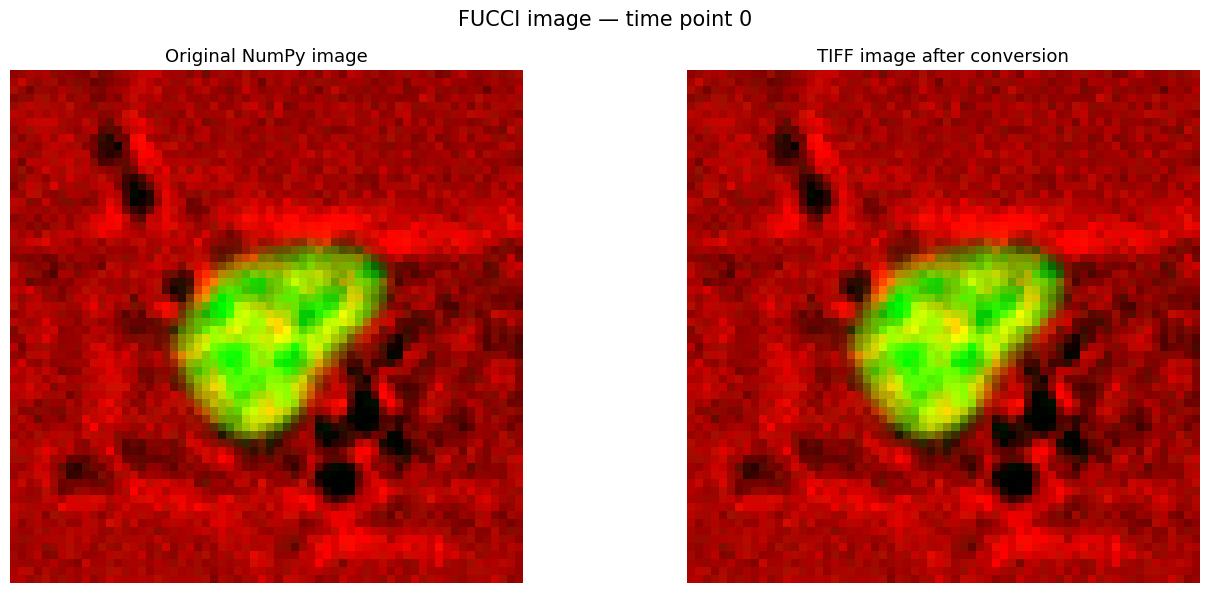

TIFF conversion results
-----------------------
Original shape: (2, 64, 64)
TIFF shape: (2, 64, 64)
Original dtype: float16
TIFF dtype: float16
Pixel values identical: True
TIFF saved at: /Users/alexiahohn/info/MA1/ML/ML_project2/ML_PhenoMe/Notebooks/tutorials/example_fucci_frame.tif


In [8]:
# --------------------------------------------------
# 1. Select one time point
# --------------------------------------------------
time_point = 0
frame = example_track[time_point]

if frame.ndim != 3 or frame.shape[0] < 2:
    raise ValueError(
        f"Expected frame shape (C, H, W) with at least 2 channels. "
        f"Received: {frame.shape}"
    )

# --------------------------------------------------
# 2. Function to normalize images for visualization 
#    (doesn't change original image data)
# --------------------------------------------------
def normalize_channel(image, percentiles=(1, 99)):
    image = image.astype(np.float32)
    low, high = np.percentile(image, percentiles)

    if high <= low:
        return np.zeros_like(image)

    return np.clip((image - low) / (high - low), 0, 1)


# --------------------------------------------------
# 3. Convert NumPy frame to TIFF and reload it
# --------------------------------------------------
tiff_path = Path("example_fucci_frame.tif")

tifffile.imwrite(tiff_path, frame, photometric="minisblack")
tiff_frame = tifffile.imread(tiff_path)

# --------------------------------------------------
# 4. Create RGB images for original and TIFF
# --------------------------------------------------
def create_rgb_image(image):
    rgb = np.zeros((*image.shape[1:], 3), dtype=np.float32)

    # Channel 0 displayed in red
    rgb[..., 0] = normalize_channel(image[0])

    # Channel 1 displayed in green
    rgb[..., 1] = normalize_channel(image[1])

    return rgb


original_rgb = create_rgb_image(frame)
tiff_rgb = create_rgb_image(tiff_frame)

# --------------------------------------------------
# 5. Display before and after conversion
# --------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(original_rgb)
axes[0].set_title("Original NumPy image", fontsize=13)

axes[1].imshow(tiff_rgb)
axes[1].set_title("TIFF image after conversion", fontsize=13)

for ax in axes:
    ax.axis("off")

plt.suptitle(
    f"FUCCI image — time point {time_point}",
    fontsize=15
)

plt.tight_layout()
plt.show()

# --------------------------------------------------
# 6. Verify conversion
# --------------------------------------------------
print("TIFF conversion results")
print("-----------------------")
print(f"Original shape: {frame.shape}")
print(f"TIFF shape: {tiff_frame.shape}")
print(f"Original dtype: {frame.dtype}")
print(f"TIFF dtype: {tiff_frame.dtype}")
print(f"Pixel values identical: {np.array_equal(frame, tiff_frame)}")
print(f"TIFF saved at: {tiff_path.resolve()}")

## Looking at the timestamps